# KOLD dataset

Kold dataset is created by School of Computing in KAIST and SoftlyAI Research as part of a research report in 2022. The report and the Github could be found below.

- Research Paper: https://aclanthology.org/2022.emnlp-main.744/
- Github: https://github.com/boychaboy/KOLD/tree/main

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk
from collections import Counter
import re

## Prepare Dataset 

In [2]:
dataset = pd.read_json('kold_v1.json') # Read json file in pandas

In [3]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 40429 entries, 0 to 40428
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   guid        40429 non-null  str           
 1   source      40429 non-null  str           
 2   date        40429 non-null  datetime64[us]
 3   title       40429 non-null  str           
 4   comment     40429 non-null  str           
 5   OFF         40429 non-null  bool          
 6   TGT         20310 non-null  str           
 7   GRP         12413 non-null  str           
 8   OFF_span    40429 non-null  str           
 9   TGT_span    40429 non-null  str           
 10  raw_labels  40429 non-null  object        
dtypes: bool(1), datetime64[us](1), object(1), str(8)
memory usage: 3.1+ MB


Kold dataset has total 40429 rows with 11 different columns that contain source, date, title, comment and the detailed information about it being hate speech or not.

In [4]:
pd.set_option('display.max_colwidth', None) # Remove text truncation for better preview the text

In [5]:
dataset.head()

,guid,source,date,title,comment,OFF,TGT,GRP,OFF_span,TGT_span,raw_labels
0,kold-v1_00000,naver_news,2021-07-25,페미니즘이 범죄가 되는 나라 [삶과 문화],남녀평등 주장할 거면 여성징병제에도 동의하라고ㅋㅋㅋ 그리고 내 말에 그냥 시비만 걸지 말고 혜택은 다 쳐받으면서 왜 차별받는다고 말하는지 말해보라고ㅋㅋㅋ,True,group,others-feminist,쳐받으면서 왜 차별받는다고 말하는지 말해보라고ㅋㅋㅋ,,"[{'offensiveness': True, 'annotator_id': 191510, 'off_start_idx': [57], 'off_end_idx': [84], 'target': [['group']], 'target_group': [['집단-성 정체성-여성']], 'tgt_start_idx': [], 'tgt_end_idx': []}, {'offensiveness': True, 'annotator_id': 192109, 'off_start_idx': [56], 'off_end_idx': [84], 'target': [['not specified', 'group']], 'target_group': [['집단-성 정체성-페미니스트', '알 수 없음']], 'tgt_start_idx': [], 'tgt_end_idx': []}, {'offensiveness': True, 'annotator_id': 193299, 'off_start_idx': [0], 'off_end_idx': [84], 'target': [['group']], 'target_group': [['집단-성 정체성-페미니스트']], 'tgt_start_idx': [], 'tgt_end_idx': []}]"
1,kold-v1_00001,naver_news,2021-04-13,[젠더의학①] 여성은 ‘몸집 작은 남성’이 아니다,의학에도 젠더 사상이 붙네 ㄷㄷ;,True,untargeted,NaN,젠더 사상이 붙네 ㄷㄷ;,,"[{'offensiveness': False, 'annotator_id': 185692}, {'offensiveness': True, 'annotator_id': 190479, 'off_start_idx': [0], 'off_end_idx': [17], 'target': [['not specified']], 'target_group': [['알 수 없음']], 'tgt_start_idx': [], 'tgt_end_idx': []}, {'offensiveness': True, 'annotator_id': 192700, 'off_start_idx': [5], 'off_end_idx': [17], 'target': [['group']], 'target_group': [['집단-성 정체성-젠더퀴어']], 'tgt_start_idx': [], 'tgt_end_idx': []}]"
2,kold-v1_00002,naver_news,2021-09-15,“책 생명 늘려야죠”… 문학 속 ‘성차별’ 패치 떼는 출판계,"루브르 박물관에 있는 모나리자 머리도 단발로 수정하고,미국에 있는 자유의 여신상도 콘크리트 부어서 가슴부분 가리자",True,group,others-feminist,"모나리자 머리도 단발로 수정하고,미국에 있는 자유의 여신상도 콘크리트 부어서 가슴부분 가리자",,"[{'offensiveness': True, 'annotator_id': 181776, 'off_start_idx': [12], 'off_end_idx': [62], 'target': [['group']], 'target_group': [['집단-성 정체성-여성']], 'tgt_start_idx': [], 'tgt_end_idx': []}, {'offensiveness': True, 'annotator_id': 183406, 'off_start_idx': [12], 'off_end_idx': [62], 'target': [['group']], 'target_group': [['집단-성 정체성-페미니스트']], 'tgt_start_idx': [], 'tgt_end_idx': []}, {'offensiveness': False, 'annotator_id': 191670}]"
3,kold-v1_00003,naver_news,2021-01-14,이루다로 촉발된 젠더 논쟁... 개인정보 유출이란 본질 외면,진짜 어이가 없네 딥페이크 만든 사람들도 처벌하고 알페스 만든 사람들도 처벌하라니깐?? 왜 알페스 얘기 꺼내면 딥페이크 얘기로 돌리려고 하는지 모르겠네 둘다 처벌 받음 되지 왜 쫄리나..?,True,untargeted,NaN,왜 쫄리나..?,,"[{'offensiveness': True, 'annotator_id': 166167, 'off_start_idx': [85], 'off_end_idx': [104], 'target': [['not specified']], 'target_group': [['알 수 없음']], 'tgt_start_idx': [], 'tgt_end_idx': []}, {'offensiveness': False, 'annotator_id': 189207}, {'offensiveness': True, 'annotator_id': 189696, 'off_start_idx': [97], 'off_end_idx': [104], 'target': [['group']], 'target_group': [['집단-성 정체성-여성']], 'tgt_start_idx': [], 'tgt_end_idx': []}]"
4,kold-v1_00004,naver_news,2021-05-06,"GS25, 브레이브걸스 포스터 또 젠더 이슈 논란",브레이브걸스=페미아이돌,True,group,others-others,페미아이돌,브레이브걸스,"[{'offensiveness': True, 'annotator_id': 188083, 'off_start_idx': [7], 'off_end_idx': [11], 'target': [['other']], 'target_group': [['기타']], 'tgt_start_idx': [0], 'tgt_end_idx': [5]}, {'offensiveness': False, 'annotator_id': 173789}, {'offensiveness': True, 'annotator_id': 188927, 'off_start_idx': [7], 'off_end_idx': [11], 'target': [['group']], 'target_group': [['집단-기타-그 외']], 'tgt_start_idx': [0], 'tgt_end_idx': [5]}]"


In [6]:
dataset['OFF'].unique()

array([ True, False])

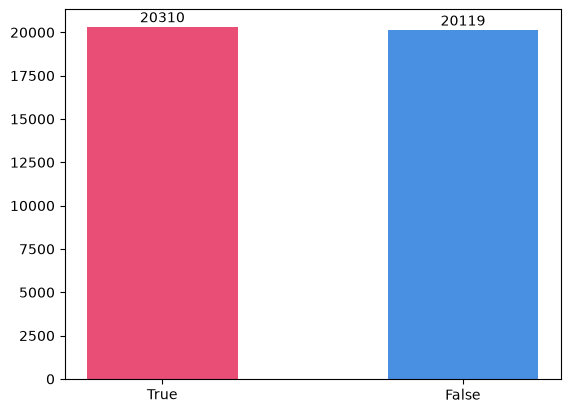

In [ ]:
label_counts = Counter(dataset['OFF'])

labels = ["True", "False"]

counts = [
    label_counts[True],
    label_counts[False]
]

bars = plt.bar(labels, counts, width=0.5, color=["#E94E77", "#4A90E2"])
plt.bar_label(bars, padding=1)
plt.show()


KOLD dataset has balanced number of labels between offensive and non-offensive. 

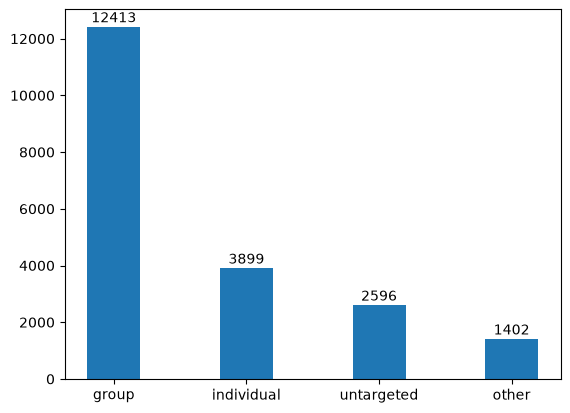

In [33]:
# Check TGT (Target Group Attribute) counts 
tgt_counts = Counter(dataset['TGT'].iloc[dataset['OFF']==True])
tgt_counts = Counter(dict(tgt_counts.most_common()))

tgt_labels = tgt_counts.keys()
counts = tgt_counts.values()

bars = plt.bar(tgt_labels, counts, width=0.4)
plt.bar_label(bars, padding=1)
plt.show()

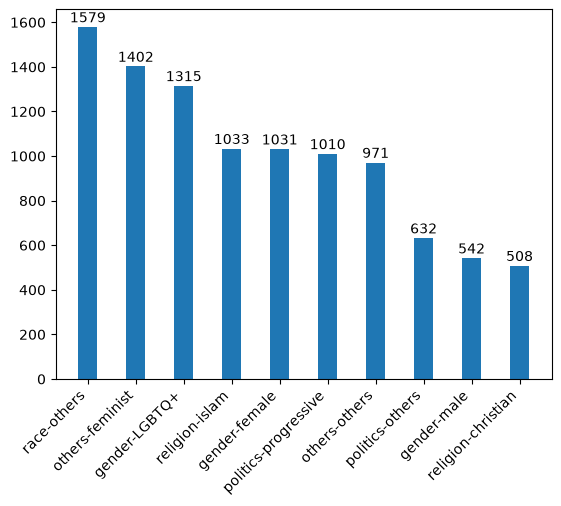

In [60]:
# Check GRP (Group) counts
grp_counts = Counter(dataset.loc[dataset['OFF'], 'GRP'].dropna())
grp_counts_top10 = Counter(dict(grp_counts.most_common(10))) # Get only the top 10 common groups

grp_labels = grp_counts_top10.keys()
counts = grp_counts_top10.values()

bars = plt.bar(grp_labels, counts, width=0.4)
plt.bar_label(bars, padding=1)
plt.xticks(rotation=45, ha='right')
plt.show()

## Data Preprocessing

### Remove Korean Stopwords

In [63]:
with open("korean_stopword.txt", "r") as koStopword:
    koStopword = koStopword.read()
    print(koStopword)


FileNotFoundError: [Errno 2] No such file or directory: 'korean_stopword.txt'